# BCECF Ratiometric pH Calibration

This notebook shows how to estimate pH from fluorescence measurements of BCECF.

BCECF is a ratiometric pH dye: its emission at 535 nm is excited at two
wavelengths (490 nm, 440 nm). The **ratio**
between fluorescence values at these reads (`490 / 440`) should track pH.

In this template, we

1. Load a calibration plate (standards at known pH) 
2. Compute the `490/440` ratio and fit a standard curve
3. Load a data plate (samples to estimate pH)
4. Standardize the data plate from fluorescence to pH, and
5. Fit kinetics using a sigmoid model with drift and a baseline offset.

The data underlying this template is attributed to our collaborator David Garenne - a DevNote on this work will be up soon!

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from cdk import logging
log = logging.setup_logging(logging.ERROR)

from cdk.instruments.platereader import load_platereader_data

## 1. Load calibration data

Here we load Gen5 exported data paired with a platemap. The platemap needs to specify the pH of each standard in a `pH` column.

In [2]:
cal = load_platereader_data(
    data_file="sample-data/pH/calibration.xlsx",
    platemap_file="sample-data/pH/calibration-platemap.csv",
    platereader='biotek'
)
print(cal)

[06/25/26 23:53:46] INFO     Found 1 plate blocks                  biotek.py:105
                    INFO     Parsing plate block 1                 biotek.py:112
                    INFO     Read metadata section, found 1 read   biotek.py:213
                             block(s).                                          
                    INFO     Parsed 1 segment(s) successfully.     biotek.py:466
                    INFO     Found 0 segment(s) that could not be  biotek.py:467
                             associated with existing read data.                
PlateReaderResult with the following 1 blocks:
0: (24, 34) endpoint read with reads: 440,535 (Fluorescence), 490,535 (Fluorescence) (Plate 'Plate 5')


In [3]:
# Take the block we want to do further analysis
desired_index = 0
calibration_data = cal[desired_index]

## 2. Calibration Curve

Now, calculate the BCECF **ratio**
(`490,535 / 440,535`), and fit a standard curve over the wells named
`"BCECF standard"`. This will perform a linear regression of `pH` to `490/440` ratio.

slope, intercept = [  2.67495596 -13.79554277]
R^2 = 0.9112


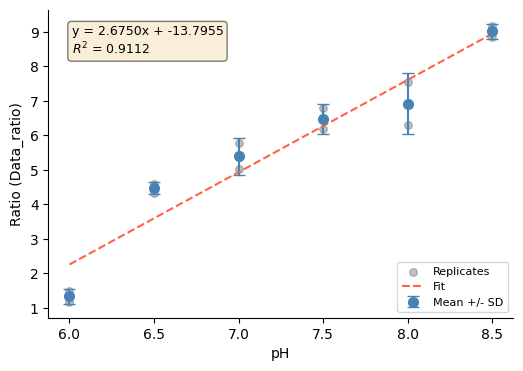

In [4]:
cal_ratio = calibration_data.ratio("490,535", "440,535")
curve = cal_ratio.fit_standard_curve(known="pH", standard_name="BCECF standard")

curve.plot()
print("slope, intercept =", curve.result.params)
print("R^2 =", round(curve.result.r_squared, 4))

# 3. Load sample data

In [5]:
sample_result = load_platereader_data(
    data_file = "sample-data/pH/data.xlsx",
    platemap_file="sample-data/pH/data-platemap.csv",
    platereader='biotek'
)

print(sample_result)

[06/25/26 23:53:48] INFO     Found 1 plate blocks                  biotek.py:105
                    INFO     Parsing plate block 1                 biotek.py:112
                    INFO     Read metadata section, found 1 read   biotek.py:213
                             block(s).                                          
                    WARNING  Data column contains non-numeric     biotek.py:1108
                             values.                                            
                    INFO     Parsed 3 segment(s) successfully.     biotek.py:466
                    INFO     Found 0 segment(s) that could not be  biotek.py:467
                             associated with existing read data.                
PlateReaderResult with the following 3 blocks:
0: (2790, 35) kinetic read with reads: 440,535 (Fluorescence) (Plate 'Plate 1')
1: (2790, 35) kinetic read with reads: 490,535 (Fluorescence) (Plate 'Plate 1')
2: (48, 33) endpoint read with reads: Max V [440,535] (Fluoresce

The output file has two blocks corresponding to the 440 and 490 reads we want, as well as a summary block we don't need. 
We can just take the two `kinetic` blocks we want:

In [6]:
sample_data = sample_result.take('kinetic')

## Convert to pH and Fit Kinetics

Calculate the `490/440` ratio on the **data** plate, then call `standardize(curve)` to estimate `pH` from the `490/440` ratio.
Then, you can plot the traces.

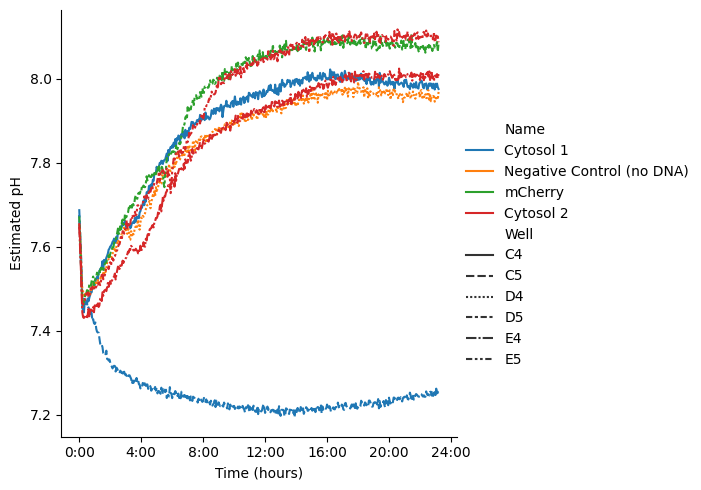

In [7]:
pH = sample_data.ratio("490,535", "440,535").standardize(curve)
pH.plot(style='Well') # gives replicates the same color but with different line styles

pH traces sit on a non-zero baseline (~6&ndash;8), so fit with
`sigmoid_drift_offset` &mdash; a sigmoid with a linear drift term **and** a
fitted constant baseline `c`. (The default `sigmoid_drift` has no constant
term and would mis-estimate the steady state and maximum velocity on a pH
trace.)

In [8]:
kinetics = pH.fit_kinetics(fit_function_name="sigmoid_drift_offset")
kinetics.summary

[06/25/26 23:53:49] INFO     Calculating Kinetics                analysis.py:223


,Well,Name,Max Velocity,Max Velocity Time,Lag Time,Steady State,Completion Time,Completion Threshold,Drift,Offset,Fit Function,R^2,Good Fit,Standardized to
0,C4,Cytosol 1,0.06,0 days 03:10:01,-1 days +21:27:27,7.99,0 days 11:34:21,0.95,-0.00,7.29,sigmoid_drift_offset,0.99,True,pH
1,C5,Cytosol 1,0.00,0 days 05:52:04,NaT,7.29,0 days 08:51:04,0.95,-0.01,7.29,sigmoid_drift_offset,0.34,False,pH
2,D4,Negative Control (no DNA),0.05,0 days 03:53:57,-1 days +22:53:34,7.91,0 days 11:16:11,0.95,0.00,7.41,sigmoid_drift_offset,0.99,True,pH
3,D5,mCherry,0.07,0 days 04:16:49,-1 days +22:42:12,8.09,0 days 12:29:27,0.95,-0.00,7.35,sigmoid_drift_offset,0.99,True,pH
4,E4,Cytosol 2,0.06,0 days 04:59:01,0 days 00:53:24,7.88,0 days 11:00:37,0.95,0.01,7.44,sigmoid_drift_offset,0.99,True,pH
5,E5,Cytosol 2,0.07,0 days 04:51:28,-1 days +22:49:31,8.09,0 days 13:44:20,0.95,-0.00,7.35,sigmoid_drift_offset,0.99,True,pH



`kinetics.plot()` overlays each fit with its max-velocity tangent,
steady-state line, and $V_\text{max}$ / lag / completion annotations.

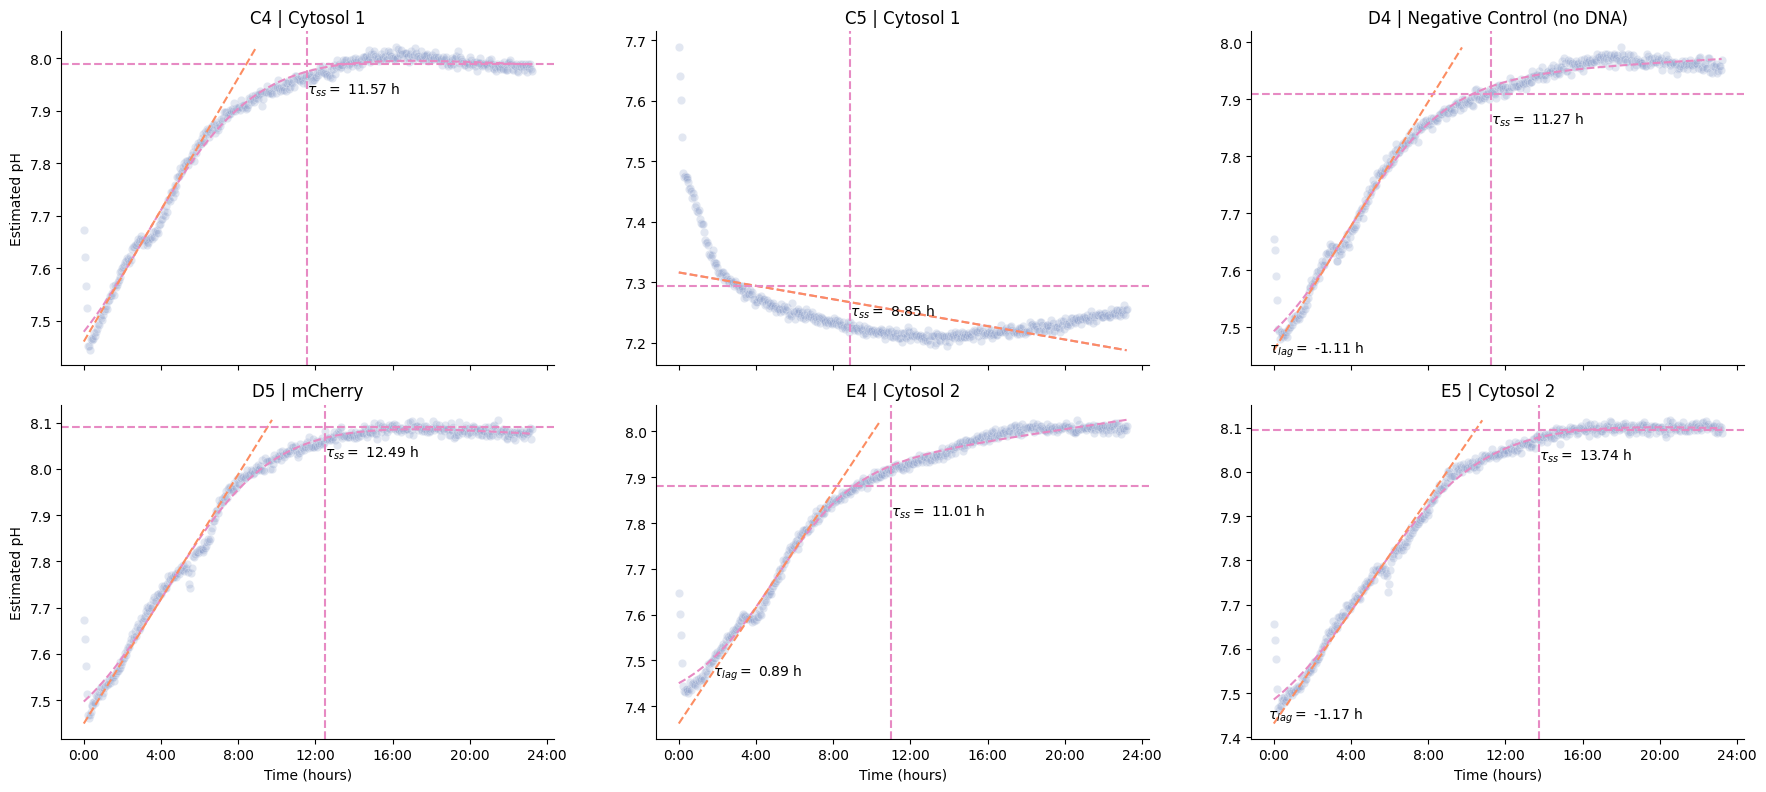

In [9]:
kinetics.plot(col='Well',facet_kws={'sharey':False})

We can see a positive correlation between steady state value and max velocity:

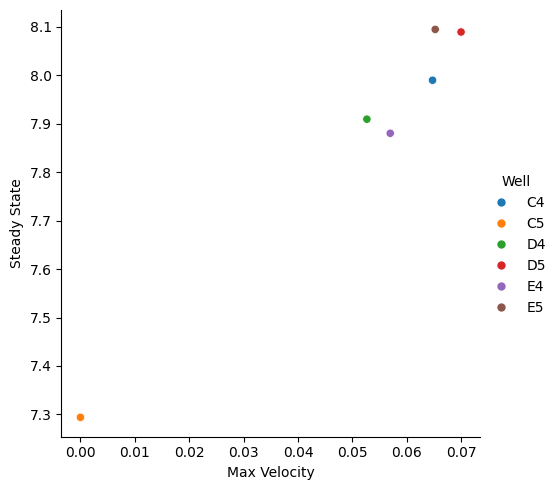

In [10]:
kinetics.plot_response(x='Max Velocity',y='Steady State', hue='Well')

---

## Interpreting the Kinetics

The fit is now in **pH units**, so the derived metrics read directly as pH:

- **Max Velocity** (`Max Velocity`) &mdash; peak rate of acidification /
  alkalinization, in **pH per hour**. The steepest slope of the trace.
- **Lag Time** (`Lag Time`) &mdash; time before the response takes off
  (back-extrapolation of the max-velocity tangent to the baseline).
- **Steady State** (`Steady State`) &mdash; the plateau **pH level**. Because
  `sigmoid_drift_offset` fits a baseline `c`, this sits on the real pH baseline
  (e.g. ~8 for a trace that starts near 6 and rises by ~2), not near zero.
- **Completion Time** (`Completion Time`) &mdash; when the response reaches the
  completion threshold fraction of its amplitude.
- **R&sup2;** / **Good Fit** &mdash; fit quality; inspect wells flagged
  `Good Fit == False`.

Use `kinetics.analysis_frame()` to join these per-well metrics back to the
platemap design variables, and `kinetics.plot_response(x=..., y="Max Velocity")`
to plot a metric against a design variable.